In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [63]:
df = pd.read_csv("deces.csv", 
     usecols=
        [
        'sexe',
        'date_naissance',
        'date_deces',
        'code_insee_deces'    
        ],
)

/tmp/ipykernel_39691/15662686.py:1: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("deces.csv",


In [78]:
df['date_naissance'] = pd.to_datetime(df['date_naissance'], format='%Y%m%d', errors='coerce')
df['date_deces'] = pd.to_datetime(df['date_deces'], format='%Y%m%d', errors='coerce')
df['code_insee_deces'] = pd.to_numeric(df['code_insee_deces'], errors='coerce')

In [79]:
invalid_count_n = df['date_naissance'].isna().sum()
invalid_count_d = df['date_deces'].isna().sum()
invalid_count_c = df['code_insee_deces'].isna().sum()
print(f'Invalid naissance: {invalid_count_n/len(df)*100:.3f}%')
print(f'Invalid deces: {invalid_count_d/len(df)*100:.3f}%')
print(f'Invalid code: {invalid_count_c/len(df)*100:.3f}%')

df_pp = df.dropna(subset=['date_naissance', 'date_deces', 'code_insee_deces'])
df_pp['code_insee_deces'] = df_pp['code_insee_deces'].astype('int')
print(f"Lost rows {(1-len(df_pp)/len(df))*100:.3f}%")
df_pp = df_pp[df_pp['date_deces'].between('1974-01-01', '2024-12-31')]
df_pp = df_pp[df_pp['date_deces'].dt.month.isin([6, 7, 8])]
df_pp['age'] = (df_pp['date_deces'] - df_pp['date_naissance']).dt.days // 365


Invalid naissance: 0.388%
Invalid deces: 0.003%
Invalid code: 0.336%


/tmp/ipykernel_39691/3957543607.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pp['code_insee_deces'] = df_pp['code_insee_deces'].astype('int')


Lost rows 0.724%


Text(0.5, 1.0, 'National mortality')

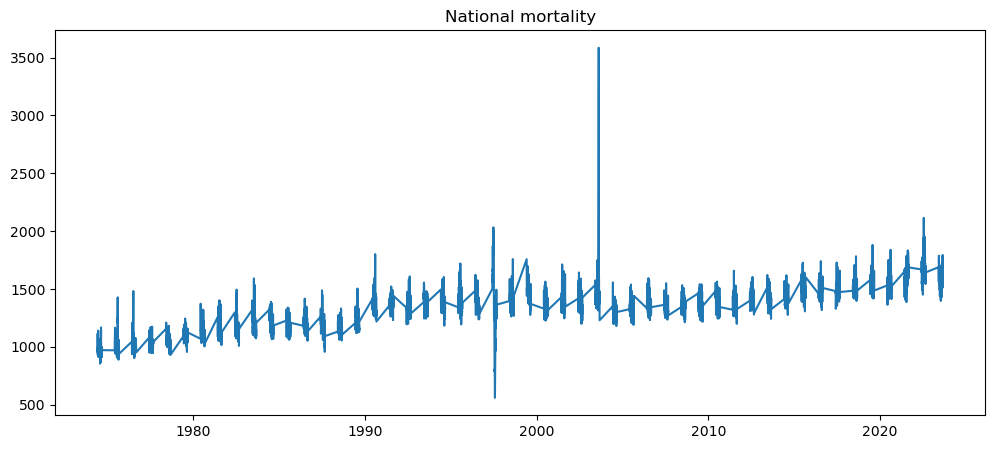

In [80]:
grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1974-06-01', end='2023-08-31', freq='D')
date_range = date_range[date_range.month.isin([6, 7, 8])]  # Keep only summer months

# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)
# Ensure count is integer
final_df['count'] = final_df['count'].astype(int)
plt.figure(figsize=(12,5))
plt.plot(final_df['date_deces'], final_df['count'])
plt.title("National mortality")

In [85]:
daily_mean

day_month
01-06    1363.82
01-07    1375.88
01-08    1339.44
02-06    1358.30
02-07    1353.68
          ...   
30-06    1354.52
30-07    1342.32
30-08    1298.18
31-07    1331.54
31-08    1302.14
Name: count, Length: 92, dtype: float64

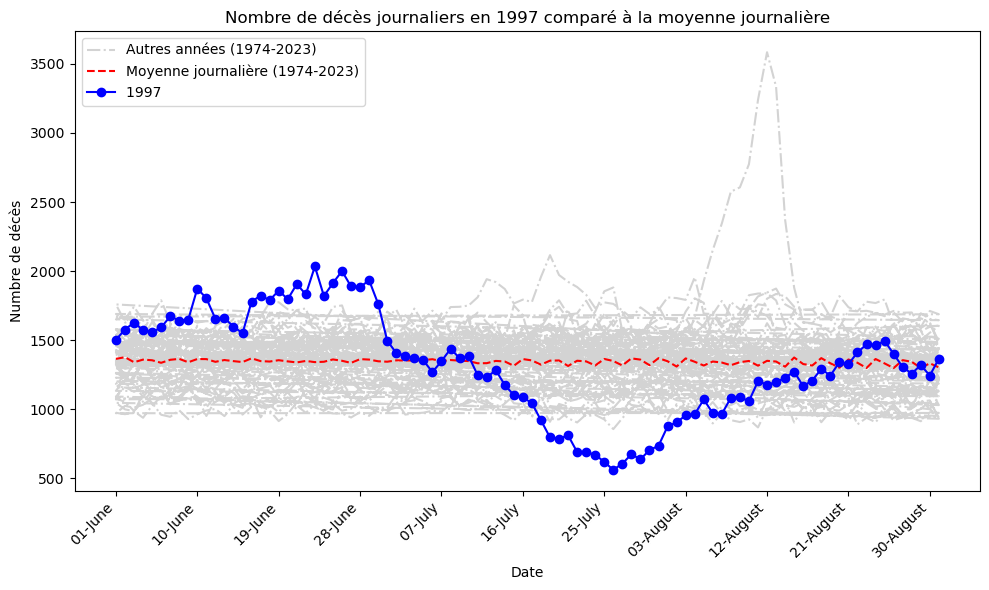

In [97]:
df_1997 = final_df[final_df['date_deces'].dt.year == 1997]
df_other_years = final_df[final_df['date_deces'].dt.year != 1997]
daily_mean = df_other_years.groupby(df_other_years['date_deces'].dt.date)['count'].mean()

final_df['day_month'] = final_df['date_deces'].dt.strftime('%d-%m')
daily_mean = final_df.groupby('day_month')['count'].mean()

plt.figure(figsize=(10, 6))
# Plot count for 1997

plt.plot(df_other_years['date_deces'].dt.strftime('%d-%B'), df_other_years['count'], linestyle='-.', color='lightgrey', label='Autres années (1974-2023)')
# Plot daily mean count for other years
plt.plot(df_1997['date_deces'].dt.strftime('%d-%B'), daily_mean.values, label='Moyenne journalière (1974-2023)', color='r', linestyle='--')
plt.plot(df_1997['date_deces'].dt.strftime('%d-%B'), df_1997['count'], marker='o', label='1997 ', color='b')

# Title and labels
plt.title('Nombre de décès journaliers en 1997 comparé à la moyenne journalière')
plt.xlabel('Date')
plt.ylabel('Numbre de décès')
plt.xticks(rotation=45, ha='right')  # Rotate and align the labels to the right
plt.xticks(ticks=range(0, len(df_1997), len(df_1997)//10)) 
plt.tight_layout()
plt.legend()
plt.savefig("deces_1997.png")
plt.show()


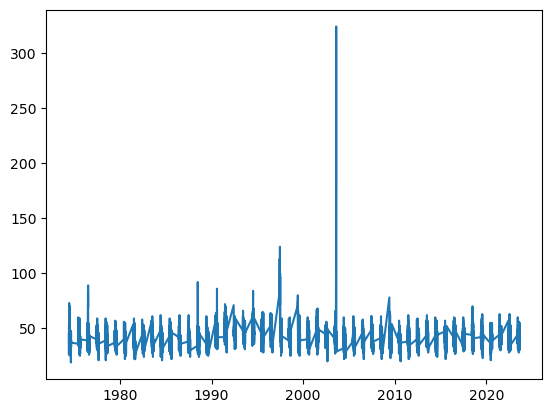

In [67]:
df_pp = df_pp[df_pp['code_insee_deces'] // 1000 == 75]

grouped_df = df_pp.groupby('date_deces').size().reset_index(name='count')
date_range = pd.date_range(start='1974-06-01', end='2023-08-31', freq='D')
date_range = date_range[date_range.month.isin([6, 7, 8])]  # Keep only summer months

# Create a complete DataFrame with all dates
complete_df = pd.DataFrame({'date_deces': date_range})

# Merge with the grouped count, filling missing counts with 0
final_df = complete_df.merge(grouped_df, on='date_deces', how='left').fillna(0)
# Ensure count is integer
final_df['count'] = final_df['count'].astype(int)
plt.plot(final_df['date_deces'], final_df['count'])

In [68]:
ts_mort = np.array(final_df['count'])
mort_yearly = np.copy(ts_mort.reshape((50, 92)))

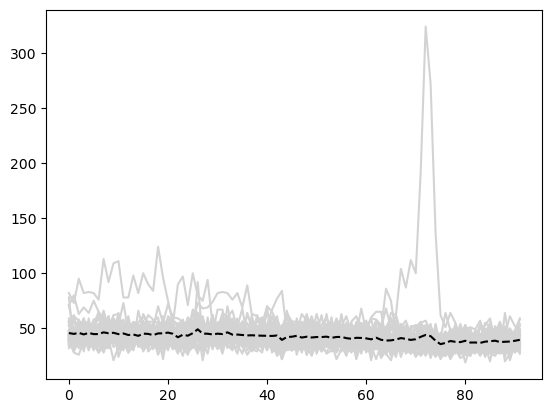

In [69]:
for year in range(50):
    plt.plot(mort_yearly[year, :], color="lightgrey")

plt.plot(np.arange(0,92), np.mean(mort_yearly, axis=(0)), ls="dashed", color="black")

In [75]:
np.save("mortality.npy", ts_mort)

<BarContainer object of 50 artists>

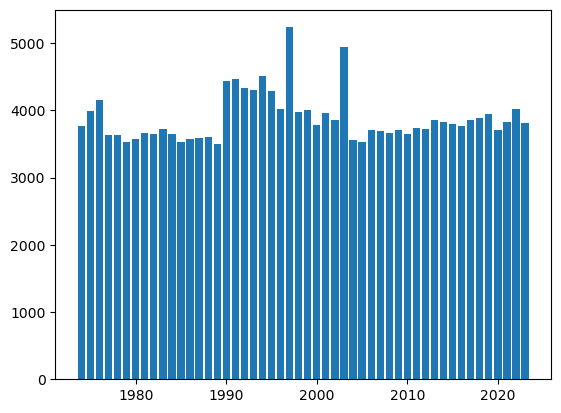

In [70]:
plt.bar(np.arange(1974,2024), np.sum(mort_yearly, axis=1))

In [76]:
# Filter data for the years 1990, 2003, and 2010
selected_years = [2003]
df_filtered = df_pp[df_pp['year_deces'].isin(selected_years)]

# Plot the age distribution with year in the legend
plt.figure(figsize=(10, 6))
sns.histplot(data=df_filtered, x='age', hue='year_deces', kde=True, bins=30, palette='Set1')

plt.title('Age Distribution at Death')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend(title='Year of Death', labels=[str(year) for year in selected_years])
plt.show()

ValueError: Could not interpret value `year_deces` for `hue`. An entry with this name does not appear in `data`.

<Figure size 1000x600 with 0 Axes>

In [72]:
selected_years = [1990, 2003, 2010]
df_filtered = df_pp[df_pp['year_deces'].isin(selected_years)]

# Plot the age distribution with year in the legend
plt.figure(figsize=(10, 6))
sns.histplot(data=df_filtered, x='age', hue='year_deces', kde=True, bins=30, palette='Set1')

plt.title('Age Distribution at Death')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend(title='Year of Death', labels=[str(year) for year in selected_years[::-1]])
plt.show()

KeyError: 'year_deces'